<a href="https://colab.research.google.com/github/ang-nc/Fisica-computacional-02/blob/main/Taller%205/T5MonteCarlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integración por Monte Carlo en FORTRAN
**Física Computacional — 106018C** · Lenguaje de cálculo: **FORTRAN 2008** · Visualización: Python

La semana pasada generamos números pseudoaleatorios y observamos sus patrones. Ahora usaremos muestras uniformes para calcular integrales. Empezaremos con ejemplos completos; al final usted completará tres programas: la convergencia del estimador de $\pi$, una integral por dos métodos y el efecto de un generador deficiente.

## Objetivos

- Transformar una muestra uniforme en $[0,1)$ a otro intervalo.
- Estimar un área contando aciertos y una integral promediando valores de una función.
- Reconocer por qué el error estadístico típico disminuye como $1/\sqrt{N}$.
- Programar y comentar los cálculos en FORTRAN; usar Python solo para las gráficas y la verificación.
- Relacionar la calidad de un generador con la calidad de una estimación física.

**Flujo:** ejecute los ejemplos en orden → complete los bloques `TODO` de los tres programas → compile y ejecute sus programas → interprete la gráfica → ejecute PASS/FAIL → redacte el informe de una página. **El notebook puede ejecutarse de principio a fin antes de completar los TODO; los resultados provisionales mostrarán FAIL hasta que los resuelva.**

## 0. Preparación de Google Colab

Colab ejecuta Python de forma nativa. Cada celda `%%writefile nombre.f90` guarda un programa FORTRAN; la siguiente lo compila con `gfortran` y ejecuta `./nombre`. Ejecute esta preparación una sola vez. Si `gfortran` ya está disponible, la instalación se omite.

In [46]:
!which gfortran || (apt-get update -qq && apt-get install -y gfortran)
!gfortran --version | head -n 1

/usr/bin/gfortran
GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Flujo de trabajo:</b> Si cambia un programa FORTRAN, ejecute otra vez su celda <code>%%writefile</code> y después la celda de compilación. El signo <code>!</code> ejecuta un comando del sistema desde Colab. Los cálculos de las integrales se harán en FORTRAN.</div>

## 1. Generador de números aleatorios en Fortran: `random_number` y `random_seed`

Fortran trae un generador incorporado. La implementación depende del compilador; las versiones actuales de GNU Fortran documentan xoshiro256**:

| Instrucción | Qué hace |
|---|---|
| `call random_number(u)` | Asigna a `u` un real uniforme en $[0,1)$. |
| `call random_seed(size=n)` | Devuelve en `n` cuántos enteros forman el estado del generador. |
| `call random_seed(put=semilla)` | Fija el estado con el arreglo `semilla` de tamaño `n`. |

La inicialización por defecto depende de la implementación. Con una semilla fija, la secuencia se repite dentro de la misma implementación: esto permite depurar y verificar una simulación (Semana 4). No se garantiza que dos compiladores o versiones produzcan los mismos números.

El cambio de intervalo es el mismo de la Semana 4: si $u \in [0,1)$, entonces $x = A + (B-A)\,u \in [A, B)$.

In [47]:
%%writefile semilla_demo.f90
! Semana 5 -- Semilla fija y cambio de intervalo con el generador de Fortran
program semilla_demo
  implicit none
  ! dp selecciona la precisión de los reales usados por el generador.
  integer, parameter :: dp = kind(1.0d0)
  integer :: i, n_sem
  integer, allocatable :: semilla(:)
  real(dp) :: u


  ! --- Tamaño del estado del generador y arreglo para la semilla ---
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  print '(a, i0)', 'Enteros en el estado del generador: ', n_sem

  ! --- Primera secuencia con semilla 2026 ---
  ! Llenamos el estado de la semilla con un valor fijo para repetir el ejemplo.
  semilla = 2026
  call random_seed(put=semilla)
  print '(a)', 'Semilla 2026:'
  do i = 1, 3
     call random_number(u)
     print '(f12.8)', u
  end do

  ! --- Se fija otra vez la misma semilla: la secuencia se repite ---
  call random_seed(put=semilla)
  print '(a)', 'Semilla 2026 otra vez:'
  do i = 1, 3
     call random_number(u)
     print '(f12.8)', u
  end do

  ! La transformación lineal duplica el ancho del intervalo y desplaza su origen.
  ! --- Cambio de intervalo: [0,1) -> [-1,1) ---
  print '(a)', 'Uniformes en [-1,1):'
  do i = 1, 3
     call random_number(u)
     print '(f12.8)', 2.0_dp*u - 1.0_dp
  end do
end program semilla_demo

Overwriting semilla_demo.f90


In [48]:
!gfortran -O2 -fcheck=all semilla_demo.f90 -o semilla_demo && ./semilla_demo

Enteros en el estado del generador: 8
Semilla 2026:
  0.47257160
  0.11463442
  0.75207116
Semilla 2026 otra vez:
  0.47257160
  0.11463442
  0.75207116
Uniformes en [-1,1):
 -0.39072870
 -0.84435708
  0.88529730


## 2. Cálculo de $\pi$ por acierto y error

Se lanzan $N$ puntos uniformes en el cuadrado $[-1,1)\times[-1,1)$ (área 4). La fracción que cae dentro del círculo de radio 1 (área $\pi$) se aproxima a $p = \pi/4$, de modo que

$$\hat\pi = 4\,\frac{N_{\rm dentro}}{N}.$$

Un punto está dentro del círculo si $x^2 + y^2 < 1$; no hace falta calcular ninguna raíz. El programa cuenta los puntos, no los guarda, e imprime la estimación cada 1000 puntos.

In [49]:
%%writefile pi_mc.f90
! Semana 5 -- Cálculo de pi por Monte Carlo (acierto y error)
! pi ~ 4 * aciertos / N, con N puntos uniformes en [-1,1) x [-1,1)
program pi_mc
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer :: n_total, n_aciertos, i, n_sem
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, pi_est

  ! --- Semilla fija: la misma corrida se puede repetir ---
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 2026
  call random_seed(put=semilla)

  ! El círculo ocupa una fracción pi/4 del cuadrado de área 4.
  n_total    = 10000
  n_aciertos = 0                       ! acumulador (contador)

  ! --- Un punto por iteración; se cuenta, no se guarda ---
  do i = 1, n_total
     call random_number(u)             ! u en [0,1)
     call random_number(v)
     x = 2.0_dp*u - 1.0_dp             ! cambio de intervalo: [0,1) -> [-1,1)
     y = 2.0_dp*v - 1.0_dp
     if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1   ! dentro del círculo

     ! --- Estimación parcial cada 1000 puntos ---
     ! mod(i,1000)=0 selecciona los múltiplos de 1000.
     if (mod(i, 1000) == 0) then
        ! real(...,dp) evita una división entera que truncaría la fracción.
        pi_est = 4.0_dp*real(n_aciertos, dp)/real(i, dp)
        print '(i8, f10.5)', i, pi_est
     end if
  end do
end program pi_mc

Overwriting pi_mc.f90


In [50]:
!gfortran -O2 -fcheck=all pi_mc.f90 -o pi_mc && ./pi_mc

    1000   3.18000
    2000   3.17600
    3000   3.18800
    4000   3.19900
    5000   3.18560
    6000   3.15933
    7000   3.15257
    8000   3.15150
    9000   3.15111
   10000   3.15800


<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Compruebe la escala:</b> Si de 100 puntos, 79 caen dentro del círculo, la estimación es <code>4 × 79/100 = 3.16</code>. Al aumentar N, las estimaciones fluctúan; no tienen que acercarse a π de manera monótona.</div>

### Visualizar los puntos y la estimación parcial

La primera gráfica muestra puntos dentro y fuera del círculo; la segunda, cómo cambia la estimación a medida que se agregan puntos de cinco corridas independientes.

In [51]:
%%writefile pi_trayectorias.f90
! Semana 5 -- Puntos de una corrida y evolución de pi_est para 5 semillas
! Salida: puntos.dat       (x, y, 1 si está dentro / 0 si está fuera)
!         trayectorias.dat (corrida, i, pi_est después de i puntos)
program pi_trayectorias
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: n_total = 20000, n_corridas = 5
  integer :: c, i, n_aciertos, n_sem, u_pts, u_tray, dentro
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, pi_est

  ! La implementación decide cuántos enteros necesita para su semilla.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  ! newunit solicita unidades libres; replace evita mezclar corridas anteriores.
  open(newunit=u_pts,  file='puntos.dat',       status='replace')
  open(newunit=u_tray, file='trayectorias.dat', status='replace')

  ! --- Ciclo externo: corridas; ciclo interno: puntos ---
  do c = 1, n_corridas
     semilla = 77 + c                      ! una semilla distinta por corrida
     call random_seed(put=semilla)
     ! Cada trayectoria empieza con contador nuevo y una semilla distinta.
     n_aciertos = 0
     do i = 1, n_total
        call random_number(u);  call random_number(v)
        x = 2.0_dp*u - 1.0_dp;  y = 2.0_dp*v - 1.0_dp
        ! Indicador 0/1 de pertenencia al círculo; se suma al contador.
        dentro = 0
        if (x*x + y*y < 1.0_dp) dentro = 1
        n_aciertos = n_aciertos + dentro
        pi_est = 4.0_dp*real(n_aciertos, dp)/real(i, dp)
        ! Conservamos cada valor parcial para mostrar la convergencia.
        write(u_tray, '(i2, i7, f10.5)') c, i, pi_est
        ! --- Solo se guardan los puntos de la primera corrida ---
        if (c == 1 .and. i <= 3000) write(u_pts, '(2f10.5, i3)') x, y, dentro
     end do
  end do
  close(u_pts);  close(u_tray)
  print '(a)', 'Archivos escritos: puntos.dat y trayectorias.dat'
end program pi_trayectorias

Overwriting pi_trayectorias.f90


In [52]:
!rm -f puntos.dat trayectorias.dat
!gfortran -O2 -fcheck=all pi_trayectorias.f90 -o pi_trayectorias && ./pi_trayectorias

Archivos escritos: puntos.dat y trayectorias.dat


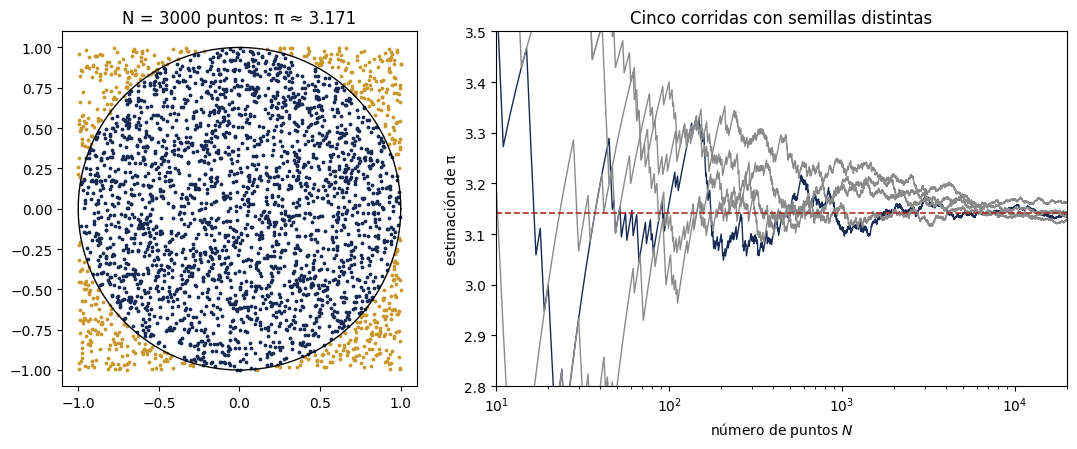

In [53]:
# Gráfica de los puntos y de las trayectorias de pi_est (lámina "Muestreo y convergencia")
import numpy as np
import matplotlib.pyplot as plt

AZUL, DORADO, ROJO, GRIS = "#162A54", "#C9972C", "#B02A20", "#8A8A8A"

pts = np.loadtxt("puntos.dat")
tray = np.loadtxt("trayectorias.dat")
dentro = pts[:, 2] == 1

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})

# --- Panel izquierdo: puntos dentro y fuera del círculo ---
ax[0].scatter(pts[dentro, 0], pts[dentro, 1], s=3, color=AZUL, label="dentro")
ax[0].scatter(pts[~dentro, 0], pts[~dentro, 1], s=3, color=DORADO, label="fuera")
t = np.linspace(0, 2*np.pi, 300)
ax[0].plot(np.cos(t), np.sin(t), "k", lw=1)
ax[0].set_aspect("equal")
ax[0].set_title(f"N = {len(pts)} puntos: π ≈ {4*dentro.mean():.3f}")

# --- Panel derecho: pi_est contra N para las 5 semillas ---
for c in range(1, 6):
    s = tray[tray[:, 0] == c]
    ax[1].plot(s[:, 1], s[:, 2], lw=1, color=AZUL if c == 1 else GRIS)
ax[1].axhline(np.pi, color=ROJO, ls="--", lw=1.2)
ax[1].set_xscale("log"); ax[1].set_xlim(10, 2e4); ax[1].set_ylim(2.8, 3.5)
ax[1].set_xlabel("número de puntos $N$"); ax[1].set_ylabel("estimación de π")
ax[1].set_title("Cinco corridas con semillas distintas")
plt.tight_layout(); plt.show()

## 3. Error estadístico del estimador

Cada lanzamiento define una variable de Bernoulli: $O_i = 1$ si el punto cae dentro (probabilidad $p = \pi/4$) y $O_i = 0$ si cae fuera. El estimador es un promedio,

$$\hat\pi = 4\,\langle O\rangle = 4\,\frac{1}{N}\sum_{i=1}^{N} O_i,$$

con la misma estructura que $\langle x\rangle$ en las pruebas del generador de la Semana 4. Para una variable de Bernoulli, $\sigma_O^2 = \langle O^2\rangle - \langle O\rangle^2 = p - p^2 = p(1-p)$. El promedio de $N$ valores independientes tiene desviación $\sigma_O/\sqrt{N}$, así que

$$\sigma_{\hat\pi} = \frac{4\sqrt{p(1-p)}}{\sqrt{N}} = \frac{1.642}{\sqrt{N}}.$$

La celda siguiente calcula esta predicción y la compara con la dispersión de las 5 trayectorias de la sección 2 en algunos valores de $N$.

**Dos tamaños distintos:** N es el número de puntos dentro de cada estimación; M es el número de corridas. La desviación entre corridas estima la incertidumbre de **una** estimación. La incertidumbre de la media de M corridas es aproximadamente esa desviación dividida por √M. Las trayectorias acumuladas contienen puntos correlacionados entre sí; para cada N se compara una estimación de cada corrida.

El TCL explica por qué la distribución de los promedios se aproxima a una gaussiana para N grande, suponiendo independencia y varianza finita. La relación σ/√N para la desviación de la media no requiere que los datos originales sean gaussianos. El Anexo A permite explorar esa distribución gráficamente.

In [54]:
# Predicción 1.642/sqrt(N) contra la dispersión de las 5 corridas de la sección 2
import numpy as np

p = np.pi/4
coef = 4*np.sqrt(p*(1 - p))
print(f"4*sqrt(p(1-p)) = {coef:.4f}\n")

tray = np.loadtxt("trayectorias.dat")
print("     N   sigma predicha   desviación de las 5 corridas")
for N in [100, 1000, 10000, 20000]:
    valores = tray[tray[:, 1] == N][:, 2]          # pi_est de cada corrida en ese N
    print(f"{N:6d}   {coef/np.sqrt(N):12.4f}   {valores.std(ddof=1):14.4f}")

4*sqrt(p(1-p)) = 1.6422

     N   sigma predicha   desviación de las 5 corridas
   100         0.1642           0.1368
  1000         0.0519           0.0476
 10000         0.0164           0.0141
 20000         0.0116           0.0135


<div style="background-color:#fdecea; border-left:5px solid #e53935; padding:10px 15px; margin:10px 0;"><b>Distinga dos tamaños:</b> <code>N</code> es el número de puntos de una estimación; <code>M</code> es el número de corridas. La dispersión entre corridas describe una estimación típica. La incertidumbre de su media es esa dispersión dividida por la raíz de M.</div>

**Consecuencia práctica.** Como $\sigma \propto 1/\sqrt{N}$, una cifra decimal más (reducir $\sigma$ por 10) exige **100 veces más puntos**. Para una precisión $\varepsilon$ se necesitan $N \approx (1.642/\varepsilon)^2$ puntos: $\sim 3\times10^4$ para $\varepsilon = 10^{-2}$ y $\sim 3\times10^8$ para $\varepsilon = 10^{-4}$.

## 4. Integración por Monte Carlo: método de valor medio

Si $x$ es uniforme en $[a,b)$, su densidad es $P(x) = 1/(b-a)$ y

$$I = \int_a^b f(x)\,dx = (b-a)\int_a^b P(x)\,f(x)\,dx = (b-a)\,\langle f\rangle \approx \frac{b-a}{N}\sum_{k=1}^{N} f(x_k).$$

El error es $\sigma_I = (b-a)\,\sigma_f/\sqrt{N}$, con $\sigma_f^2 = \langle f^2\rangle - \langle f\rangle^2$.

**Ejemplo.** $I = \int_0^1 x^2\,dx = 1/3$. Aquí $\langle f\rangle = 1/3$ y $\langle f^2\rangle = \int_0^1 x^4\,dx = 1/5$, de modo que $\sigma_f = \sqrt{1/5 - 1/9} = 0.298$ y el error esperado es $0.298/\sqrt{N}$.

El método de acierto y error de la sección 2 también calcula integrales: se lanzan puntos en un rectángulo $[a,b)\times[0,H)$ que contiene la curva, suponiendo $0\le f(x)\le H$ en todo el intervalo y se cuentan los que quedan debajo, $I \approx (b-a)\,H\,N_{\rm bajo}/N$.

In [55]:
%%writefile integral_x2.f90
! Semana 5 -- Integral de x^2 en [0,1) por el método de valor medio (valor exacto: 1/3)
program integral_x2
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  ! sigma_f es la desviación de x^2 en [0,1]; sigma de la integral ~ sigma_f/sqrt(N).
  real(dp), parameter :: a = 0.0_dp, b = 1.0_dp, sigma_f = 0.298142_dp
  integer :: k, n_sem
  integer(8) :: i, n_total
  integer, allocatable :: semilla(:)
  real(dp) :: u, x, suma_f, integral

  ! Una semilla fija facilita reproducir la demostración con el mismo compilador.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 2026
  call random_seed(put=semilla)

  print '(a)', '        N    integral       |error|   0.298/sqrt(N)   |error|/sigma'
  ! Repetimos para N = 10^2, 10^3, ..., 10^6; el generador sigue avanzando.
  do k = 2, 6
     n_total = 10_8**k
     suma_f = 0.0_dp                       ! acumulador de f(x_k)
     do i = 1, n_total
        call random_number(u)
        x = a + (b - a)*u                  ! x uniforme en [a,b)
        suma_f = suma_f + x*x              ! f(x) = x^2
     end do
     ! La integral es ancho del intervalo por promedio de f(x).
     integral = (b - a)*suma_f/real(n_total, dp)
     ! Comparamos error observado con la escala estadística predicha,
     ! sin esperar que el cociente error/sigma sea exactamente uno.
     print '(i9, f12.6, 2f14.6, f12.2)', n_total, integral, abs(integral - 1.0_dp/3.0_dp), &
           sigma_f/sqrt(real(n_total, dp)), &
           abs(integral - 1.0_dp/3.0_dp)/(sigma_f/sqrt(real(n_total, dp)))
  end do
end program integral_x2

Overwriting integral_x2.f90


In [56]:
!gfortran -O2 -fcheck=all integral_x2.f90 -o integral_x2 && ./integral_x2

        N    integral       |error|   0.298/sqrt(N)   |error|/sigma
      100    0.331323      0.002010      0.029814        0.07
     1000    0.348170      0.014836      0.009428        1.57
    10000    0.332038      0.001295      0.002981        0.43
   100000    0.331745      0.001588      0.000943        1.68
  1000000    0.332670      0.000663      0.000298        2.23


<div style="background-color:#fdecea; border-left:5px solid #e53935; padding:10px 15px; margin:10px 0;"><b>Evite la división entera:</b> Al formar un promedio o una fracción en FORTRAN convierta el contador con <code>real(n,dp)</code> o utilice un numerador real. Una división de dos enteros descarta la parte fraccionaria.</div>

## 5. Efecto del generador: el LCG $(57, 1, 256)$

En la Semana 4 se vio que el generador lineal congruente

$$r_{i+1} = (a\,r_i + c) \bmod M, \qquad x_i = r_i/M, \qquad (a, c, M) = (57, 1, 256)$$

tiene período máximo (256), pero sus pares consecutivos $(x_i, x_{i+1})$ caen en unas pocas líneas paralelas. En Fortran, el LCG se programa con aritmética entera y la función `mod`. El programa siguiente escribe en `lcg_pares.dat` los puntos $(x, y)$ en $[-1,1)^2$ que se forman tomando los números de dos en dos, como en el programa de $\pi$.

In [57]:
%%writefile lcg_pares.f90
! Semana 5 -- Puntos (x, y) formados con números consecutivos del LCG (57, 1, 256)
program lcg_pares
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  ! El estado toma solo 256 valores enteros; un módulo tan pequeño deja patrones.
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: i, r, u_dat
  real(dp) :: x, y

  r = 10                                         ! semilla del LCG
  ! Escribimos las parejas para graficar su distribución en el plano.
  open(newunit=u_dat, file='lcg_pares.dat', status='replace')
  do i = 1, 1000
     r = mod(a_lcg*r + c_lcg, M_lcg)             ! primer número del par
     ! Normalizamos r/M a [0,1) y luego lo llevamos a [-1,1).
     x = 2.0_dp*real(r, dp)/M_lcg - 1.0_dp
     ! Avanzar el estado otra vez da la segunda coordenada del mismo punto.
     r = mod(a_lcg*r + c_lcg, M_lcg)             ! segundo número del par
     y = 2.0_dp*real(r, dp)/M_lcg - 1.0_dp
     write(u_dat, '(2f10.5)') x, y
  end do
  close(u_dat)
  print '(a)', 'Archivo escrito: lcg_pares.dat (1000 puntos)'
end program lcg_pares

Overwriting lcg_pares.f90


In [58]:
!rm -f lcg_pares.dat
!gfortran -O2 -fcheck=all lcg_pares.f90 -o lcg_pares && ./lcg_pares

Archivo escrito: lcg_pares.dat (1000 puntos)


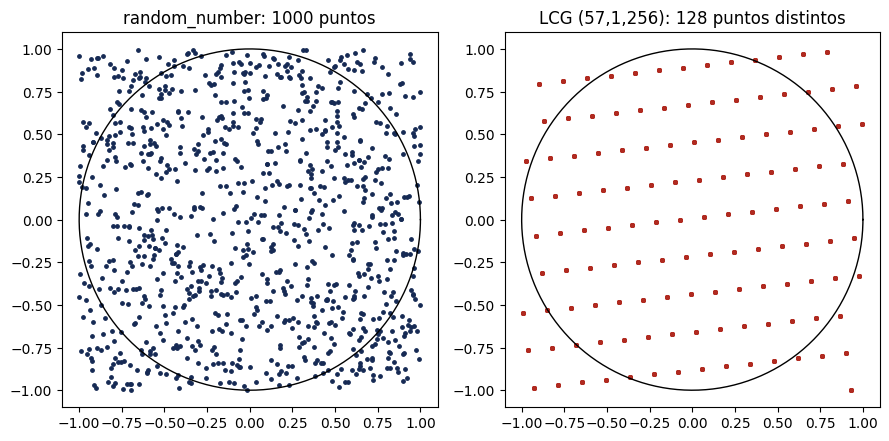

In [59]:
# Puntos del LCG (57, 1, 256) frente a puntos de random_number
import numpy as np
import matplotlib.pyplot as plt

AZUL, ROJO = "#162A54", "#B02A20"
lcg = np.loadtxt("lcg_pares.dat")
pts = np.loadtxt("puntos.dat")[:1000]
n_distintos = len(np.unique(lcg, axis=0))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
t = np.linspace(0, 2*np.pi, 300)
for a_, datos, color, titulo in [(ax[0], pts, AZUL, "random_number: 1000 puntos"),
                                 (ax[1], lcg, ROJO, f"LCG (57,1,256): {n_distintos} puntos distintos")]:
    a_.scatter(datos[:, 0], datos[:, 1], s=6, color=color)
    a_.plot(np.cos(t), np.sin(t), "k", lw=1)
    a_.set_aspect("equal"); a_.set_title(titulo)
plt.tight_layout(); plt.show()

El LCG del ejemplo tiene pocos estados: aunque produce valores en el intervalo correcto, sus parejas repiten un patrón. La observación conecta el generador de la semana anterior con el muestreo que acabamos de emplear. En la Parte C del taller se calcula $\hat\pi$ con estos puntos.

# Taller 5 — Cálculo de $\pi$ y convergencia

## Propósito

Mida en FORTRAN cómo disminuye el error del estimador de $\pi$ al aumentar $N$, compare dos métodos para calcular $\int_0^{\pi/2}\sin x\,dx = 1$ y analice el efecto de un generador deficiente sobre la estimación de $\pi$. No se requieren archivos de entrada externos.

Las plantillas fijan parámetros, declaran variables y escriben los resultados. Los bloques `TODO` describen lo que debe obtener, remitiendo a las secciones anteriores; la forma de programarlo la decide usted. Mientras estén vacíos, las salidas usan el valor provisional **−1** para indicar que la estimación aún no se ha calculado. Así puede ejecutar las celdas en orden sin producir valores indefinidos. PASS/FAIL debe mostrar FAIL hasta completar el trabajo.

## Parte A — Convergencia del estimador de $\pi$

Para cada $N = 10^2, 10^3, \ldots, 10^7$, repita el cálculo de $\hat\pi$ de la sección 2 con $M = 20$ semillas distintas. Si las estimaciones son $\hat\pi_1, \ldots, \hat\pi_M$, su media y su desviación estándar muestral son
$$\bar\pi = \frac1M\sum_{j=1}^M \hat\pi_j, \qquad
s = \sqrt{\frac{M}{M-1}\left(\frac1M\sum_{j=1}^M \hat\pi_j^2 - \bar\pi^2\right)}.$$
Distinga $s$, que describe una corrida típica, de $s/\sqrt M$, que describe la incertidumbre de la media de las $M$ corridas. La sección 3 predice $s \approx 1.642/\sqrt{N}$.

Si el error decrece como $1/\sqrt{N}$, los puntos $(\log_{10} N, \log_{10} s)$ caen sobre una recta de pendiente $-1/2$. La pendiente de $n$ puntos $(X_k, Y_k)$ por mínimos cuadrados (Semana 3) es
$$m = \frac{n\sum X_k Y_k - \sum X_k \sum Y_k}{n\sum X_k^2 - \left(\sum X_k\right)^2}.$$

Complete los **cinco bloques TODO** de `taller5_pi.f90`. El programa guarda en `convergencia.dat` el valor de $N$, la media y la desviación, y en `pendiente.dat` la pendiente $m$. El caso $N = 10^7$ tarda unos segundos. Al depurar puede reducir temporalmente el límite superior del ciclo en `k`; restáurelo a 7 antes de entregar.

In [60]:

%%writefile taller5_pi.f90
! Taller 5: Convergencia del estimador de pi mediante el metodo de acierto y error.
! Objetivo: estudiar como cambia la estimacion de pi al aumentar el numero de puntos.
! Archivos de salida:
!   convergencia.dat: contiene N, la media y la desviacion estandar de cada N.
!   pendiente.dat: contiene la pendiente del ajuste lineal entre log10(desviacion) y log10(N).

program taller5_pi
  implicit none

  ! Define la precision numerica utilizada para los calculos reales.
  ! La precision doble ayuda a reducir los errores de redondeo.
  integer, parameter :: dp = kind(1.0d0)

  ! Numero de corridas independientes realizadas para cada tamano de muestra.
  integer, parameter :: M = 20

  ! Variables enteras para controlar los ciclos, las unidades de archivo
  ! y la cantidad de puntos utilizados en el ajuste lineal.
  integer :: k, j, n_sem, u_dat, n_puntos

  ! Contadores enteros de 8 bytes para manejar cantidades grandes de puntos.
  ! n_total es el numero de puntos y n_aciertos cuenta los puntos dentro del circulo.
  integer(8) :: i, n_total, n_aciertos

  ! Arreglo que almacena la semilla usada para inicializar el generador aleatorio.
  integer, allocatable :: semilla(:)

  ! Variables reales para generar coordenadas, calcular pi y obtener estadisticas.
  ! u y v son numeros aleatorios; x e y son coordenadas del cuadrado.
  ! pi_est es una estimacion de pi; suma y suma2 acumulan las estimaciones.
  real(dp) :: u, v, x, y, pi_est, suma, suma2, media, desv

  ! Variables para el ajuste lineal de log10(desv) frente a log10(N).
  ! X_k e Y_k son los datos transformados y las demas variables acumulan sumas.
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente

  ! Consulta cuantos enteros necesita el generador para almacenar la semilla.
  call random_seed(size=n_sem)

  ! Reserva memoria para guardar todos los elementos de la semilla.
  allocate(semilla(n_sem))

  ! Inicializa en cero las sumas del ajuste por minimos cuadrados.
  ! n_puntos cuenta cuantos tamanos de muestra se analizaran.
  sx = 0.0_dp
  sy = 0.0_dp
  sxx = 0.0_dp
  sxy = 0.0_dp
  n_puntos = 0

  ! Crea o reemplaza el archivo donde se guardaran los resultados estadisticos.
  open(newunit=u_dat, file='convergencia.dat', status='replace')

  ! Recorre los tamanos de muestra N = 10^2, 10^3, ..., 10^7.
  ! Cada valor permite estudiar el efecto de aumentar el numero de puntos.
  do k = 2, 7
     n_total = 10_8**k

     ! Reinicia las sumas antes de comenzar las M corridas de este N.
     suma = 0.0_dp
     suma2 = 0.0_dp

     ! Realiza M estimaciones independientes para calcular su media y dispersion.
     do j = 1, M

        ! Asigna una semilla diferente a cada combinacion de k y j.
        ! Esto permite obtener secuencias distintas entre las corridas.
        semilla = 1000*k + j
        call random_seed(put=semilla)

        ! Valor provisional de la estimacion, que se reemplaza tras el calculo.
        pi_est = -1.0_dp

        ! A1: estimacion de pi mediante el metodo de acierto y error.
        ! Se generan puntos uniformes en el cuadrado [-1,1) x [-1,1).
        ! La proporcion de puntos dentro del circulo unitario aproxima pi/4.
        n_aciertos = 0

        ! Genera y evalua cada uno de los N puntos aleatorios.
        do i = 1, n_total

           ! Genera dos numeros aleatorios entre 0 y 1.
           call random_number(u)
           call random_number(v)

           ! Transforma los numeros para obtener coordenadas entre -1 y 1.
           x = 2.0_dp*u - 1.0_dp
           y = 2.0_dp*v - 1.0_dp

           ! Comprueba si el punto esta dentro del circulo unitario:
           ! x^2 + y^2 < 1. Si se cumple, aumenta el contador de aciertos.
           if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1

        end do

        ! Calcula pi como cuatro veces la proporcion de puntos dentro del circulo.
        ! real(..., dp) convierte los contadores a reales de precision dp
        ! para realizar una division real y no una division entera.
        pi_est = 4.0_dp*real(n_aciertos, dp)/real(n_total, dp)

        ! A2: acumula las estimaciones y sus cuadrados.
        ! Estas sumas permiten calcular la media y la desviacion estandar muestral.
        suma  = suma  + pi_est
        suma2 = suma2 + pi_est**2

     end do

     ! Inicializa las variables estadisticas con valores provisionales.
     media = -1.0_dp
     desv = -1.0_dp

     ! A3: calcula la media de las M estimaciones de pi.
     media = suma/real(M, dp)

     ! Calcula la desviacion estandar muestral usando la suma de cuadrados.
     ! El factor M/(M-1) aplica la correccion muestral de Bessel.
     ! La desviacion mide la dispersion de las estimaciones entre corridas.
     desv = sqrt(real(M, dp)/real(M-1, dp) * &
            (suma2/real(M, dp) - media**2))

     ! Guarda N, la media y la desviacion en el archivo de resultados.
     ! El formato escribe un entero y dos numeros reales en notacion cientifica.
     write(u_dat,'(i10,2es25.16e3)') n_total, media, desv

     ! Muestra en pantalla los resultados de cada tamano de muestra.
     print '(i10,2f12.6)', n_total, media, desv

     ! A4: transforma los datos a escala logaritmica para estudiar la convergencia.
     ! Si la desviacion disminuye aproximadamente como N^m, la pendiente m
     ! puede estimarse mediante un ajuste lineal en escala logaritmica.
     X_k = log10(real(n_total, dp))
     Y_k = log10(desv)

     ! Acumula las sumas necesarias para calcular la pendiente por minimos cuadrados.
     sx  = sx  + X_k
     sy  = sy  + Y_k
     sxx = sxx + X_k*X_k
     sxy = sxy + X_k*Y_k

     ! Registra un nuevo punto para el ajuste lineal.
     n_puntos = n_puntos + 1

  end do

  ! Cierra el archivo una vez guardados todos los resultados.
  close(u_dat)

  ! Inicializa la pendiente con un valor provisional antes de calcularla.
  pendiente = -1.0_dp

  ! A5: calcula la pendiente del ajuste lineal por minimos cuadrados.
  ! Esta expresion utiliza las sumas acumuladas de X, Y, X^2 y X*Y.
  pendiente = (real(n_puntos, dp)*sxy - sx*sy) / &
              (real(n_puntos, dp)*sxx - sx*sx)

  ! Crea o reemplaza el archivo que contiene la pendiente obtenida.
  open(newunit=u_dat, file='pendiente.dat', status='replace')

  ! Guarda la pendiente en notacion cientifica y cierra el archivo.
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)

  ! Presenta la pendiente en pantalla para facilitar su interpretacion.
  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente

end program taller5_pi


Overwriting taller5_pi.f90


In [61]:

# Elimina los archivos de resultados de una ejecucion anterior,
# para evitar confundir los datos antiguos con los nuevos resultados.
!rm -f convergencia.dat pendiente.dat

# Compila el codigo fuente de Fortran:
# -std=f2008: utiliza el estandar Fortran 2008.
# -O2: activa optimizaciones para mejorar la velocidad de ejecucion.
# -fcheck=all: activa comprobaciones adicionales durante la ejecucion.
# -o taller5_pi: establece el nombre del programa ejecutable.
# Si la compilacion termina correctamente, && ejecuta el programa.
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi


       100    3.134000    0.161714
      1000    3.126600    0.049779
     10000    3.137260    0.015822
    100000    3.142696    0.003486
   1000000    3.141116    0.002166
  10000000    3.141530    0.000400
Pendiente de log10(s) contra log10(N):   -0.5079


<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> con $N = 100$ cada estimación de $\pi$ debe estar entre 0 y 4, y la desviación de las 20 corridas debería ser del orden de $0.16$. Con $N = 10^7$, la media debería coincidir con $\pi$ en al menos tres decimales.</div>

In [62]:

# Importa NumPy para leer los resultados de Fortran y realizar
# operaciones numericas, como raices cuadradas y comparaciones.
import numpy as np

# Lee el archivo convergencia.dat, que contiene tres columnas:
# N: numero de puntos utilizados en cada estimacion.
# media: promedio de las estimaciones de pi en las 20 corridas.
# desv: desviacion estandar muestral de las estimaciones.
# ndmin=2 garantiza que los datos se interpreten como una matriz,
# incluso si el archivo contiene una sola fila.
# .T transpone la matriz para guardar cada columna en una variable.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

# Lee la pendiente calculada por el programa de Fortran.
# Este valor representa la pendiente del ajuste de log10(desv)
# en funcion de log10(N).
m = np.loadtxt('pendiente.dat')

# Muestra la desviacion estandar para N=100 y la compara con
# el valor aproximado esperado, calculado mediante 1.642/sqrt(N).
print(f"N=100:  desv={desv[0]:.5f}  (esperada ~{1.642/np.sqrt(100):.5f})")

# Compara la media de las estimaciones para N=10^7 con el valor
# de pi de NumPy. La diferencia absoluta mide que tan lejos
# esta el resultado experimental del valor de referencia.
print(f"N=1e7:  media={media[-1]:.6f}  pi={np.pi:.6f}  |diferencia|={abs(media[-1]-np.pi):.6f}")

# Muestra la pendiente obtenida y el valor teorico aproximado.
# En Monte Carlo, la desviacion estandar suele disminuir como
# 1/sqrt(N), por lo que la pendiente esperada es cercana a -0.5.
print(f"Pendiente: m={m:.4f}  (esperada ~ -0.5)")

# Verifica que todas las medias esten entre 0 y 4.
# La estimacion de pi mediante este metodo es cuatro veces
# una proporcion, por lo que debe estar dentro de ese intervalo.
print("¿Medias entre 0 y 4?", bool(np.all((media > 0) & (media < 4))))

# Comprueba que todas las desviaciones estandar sean positivas.
# Una desviacion igual a cero indicaria que no existe dispersion
# entre las estimaciones de las corridas correspondientes.
print("¿Desviaciones positivas?", bool(np.all(desv > 0)))

# Comprueba si la desviacion para N=100 esta cerca de 0.164.
# Se acepta una diferencia absoluta menor que 0.05 respecto
# a ese valor de referencia.
print("¿Desv. con N=100 del orden de 0.16?", abs(desv[0] - 0.164) < 0.05)

# Verifica si la media para N=10^7 se aproxima a pi con una
# tolerancia absoluta de 0.0005.
print("¿Media con N=1e7 coincide con pi en 3 decimales?", abs(media[-1] - np.pi) < 5e-4)

# Comprueba si la pendiente obtenida esta entre -0.6 y -0.4.
# Este intervalo permite evaluar si es razonablemente cercana
# al valor teorico esperado de -0.5.
print("¿Pendiente cercana a -0.5?", -0.6 < m < -0.4)


N=100:  desv=0.16171  (esperada ~0.16420)
N=1e7:  media=3.141530  pi=3.141593  |diferencia|=0.000062
Pendiente: m=-0.5079  (esperada ~ -0.5)
¿Medias entre 0 y 4? True
¿Desviaciones positivas? True
¿Desv. con N=100 del orden de 0.16? True
¿Media con N=1e7 coincide con pi en 3 decimales? True
¿Pendiente cercana a -0.5? True


### Visualización de la Parte A

La gráfica usa exclusivamente `convergencia.dat` producido por FORTRAN. Compare la desviación medida con la predicción $1.642/\sqrt{N}$.

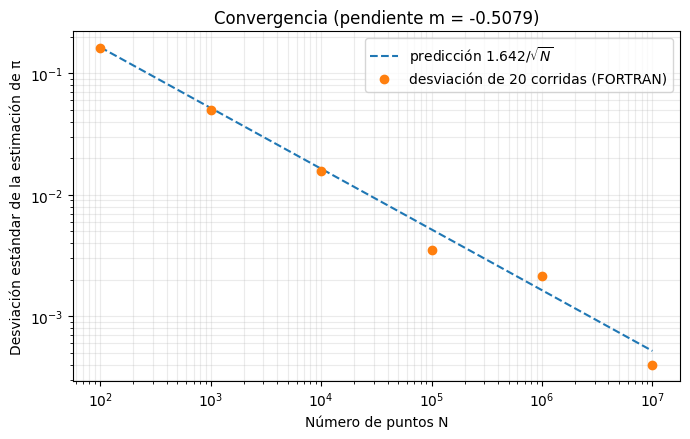

In [63]:
import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T
# valor de la pendiente (cargado directamente como escalar)
m = np.loadtxt('pendiente.dat')
plt.figure(figsize=(7,4.5))
plt.loglog(N, 1.642/np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')
if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', label='desviación de 20 corridas (FORTRAN)')
plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.title(f'Convergencia (pendiente m = {m:.4f})')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()

## Parte B — Integral en 1D por dos métodos

En el método de **valor medio**, tome $x=a+(b-a)u$ con $u$ uniforme en $[0,1)$ y estime
$$I_\mathrm{VM}=\frac{b-a}{N}\sum_{i=1}^{N}\sin x_i.$$

En **acierto y error**, construya puntos $(x,y)$ uniformes en el rectángulo $[0,\pi/2)\times[0,1)$, cuente los puntos que cumplen $y<\sin x$ y estime
$$I_\mathrm{AE}=(b-a)\frac{N_\mathrm{bajo}}{N}.$$

Para comparar los métodos, repita cada cálculo $R$ veces y obtenga la media y la desviación estándar muestral de las $R$ estimaciones, con las mismas fórmulas de la Parte A.

Complete los **cuatro bloques TODO** de `taller5_seno.f90`. Cada repetición calcula las dos integrales con $N=1000$ puntos; se realizan $R=1000$ repeticiones para medir la dispersión de los estimadores. El programa guarda en `seno.dat` la media y la desviación estándar muestral de cada método. Compare las medias con 1 y las dispersiones con $0.483/\sqrt{N}$ (valor medio) y $0.756/\sqrt{N}$ (acierto y error). Al depurar puede disminuir temporalmente `R`; restáurelo a 1000 antes de entregar.

In [64]:

%%writefile taller5_seno.f90
! Taller 5: calculo de la integral de sin(x) en [0, pi/2)
! mediante los metodos de valor medio y de acierto y error.
! Objetivo: comparar las estimaciones y la dispersion de ambos metodos.
! Archivo de salida: seno.dat, con media y desviacion estandar de cada metodo.

program taller5_seno
  implicit none

  ! Define la precision doble que se utilizara en los calculos reales.
  integer, parameter :: dp = kind(1.0d0)

  ! N es el numero de muestras utilizadas en cada estimacion.
  ! R es el numero de repeticiones independientes del experimento.
  integer, parameter :: N = 1000, R = 1000

  ! Define los limites de integracion.
  ! a = 0 y b = pi/2, calculado como 2*atan(1).
  ! H = 1 es la altura del rectangulo utilizado en acierto y error.
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp

  ! Variables enteras para controlar las repeticiones y las muestras.
  ! n_bajo cuenta los puntos ubicados debajo de la curva seno.
  ! n_sem almacena el tamano requerido para la semilla del generador.
  ! u_dat identifica el archivo de salida.
  integer :: rep, i, n_bajo, n_sem, u_dat

  ! Arreglo que almacena la semilla utilizada para inicializar
  ! el generador de numeros pseudoaleatorios.
  integer, allocatable :: semilla(:)

  ! Variables para los numeros aleatorios y las coordenadas de los puntos.
  ! suma_f acumula los valores de sin(x) en el metodo de valor medio.
  ! I_vm e I_ae almacenan las estimaciones de cada metodo en una repeticion.
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae

  ! Acumuladores de las estimaciones y sus cuadrados para ambos metodos.
  ! Se usan para calcular las medias y desviaciones estandar al final.
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae
  real(dp) :: media_vm, desv_vm, media_ae, desv_ae

  ! Consulta el tamano necesario para el arreglo de la semilla.
  ! Este tamano puede depender de la implementacion de Fortran.
  call random_seed(size=n_sem)

  ! Reserva memoria para almacenar la semilla completa.
  allocate(semilla(n_sem))

  ! Establece una semilla fija para que la secuencia pseudoaleatoria
  ! pueda reproducirse con la misma implementacion y condiciones.
  semilla = 314
  call random_seed(put=semilla)

  ! Inicializa en cero los acumuladores de ambos metodos.
  ! Esto permite sumar las estimaciones de las R repeticiones
  ! sin incluir valores residuales de calculos anteriores.
  s_vm = 0.0_dp
  s2_vm = 0.0_dp
  s_ae = 0.0_dp
  s2_ae = 0.0_dp

  ! Repite el experimento R veces para estudiar la dispersion
  ! estadistica de las estimaciones obtenidas por cada metodo.
  do rep = 1, R

     ! B1: metodo de valor medio.
     ! Reinicia la suma de los valores de la funcion seno
     ! antes de comenzar una nueva estimacion.
     suma_f = 0.0_dp

     ! Genera N puntos aleatorios en el intervalo [a,b).
     do i = 1, N

        ! Genera un numero aleatorio u entre 0 y 1.
        call random_number(u)

        ! Transforma u para obtener un punto x dentro del intervalo.
        x = a + (b - a)*u

        ! Evalua sin(x) y acumula el resultado para calcular su promedio.
        suma_f = suma_f + sin(x)

     end do

     ! Calcula la integral aproximada multiplicando el promedio
     ! de los valores de sin(x) por la longitud del intervalo.
     I_vm = (b - a) * (suma_f / real(N, dp))

     ! B2: metodo de acierto y error.
     ! Reinicia el contador de puntos situados debajo de la curva.
     n_bajo = 0

     ! Genera N puntos aleatorios dentro del rectangulo
     ! [a,b) x [0,H), que contiene la region bajo la curva seno.
     do i = 1, N

        ! Genera dos numeros aleatorios para construir las coordenadas.
        call random_number(u)
        call random_number(v)

        ! Calcula la coordenada horizontal x dentro del intervalo [a,b).
        x = a + (b - a)*u

        ! Calcula la coordenada vertical y dentro del intervalo [0,H).
        y = H*v

        ! Si y es menor que sin(x), el punto queda debajo de la curva.
        ! En ese caso, se incrementa el contador de aciertos.
        if (y < sin(x)) n_bajo = n_bajo + 1

     end do

     ! Estima la integral como el area del rectangulo multiplicada
     ! por la proporcion de puntos que quedaron debajo de la curva.
     I_ae = (b - a) * H * (real(n_bajo, dp) / real(N, dp))

     ! B3: acumula las estimaciones de valor medio y acierto y error.
     ! Tambien acumula sus cuadrados para calcular la desviacion estandar.
     s_vm = s_vm + I_vm
     s2_vm = s2_vm + I_vm**2

     s_ae = s_ae + I_ae
     s2_ae = s2_ae + I_ae**2

  end do

  ! B4: calcula la media de las R estimaciones de cada metodo.
  ! La media resume el valor central obtenido en las repeticiones.
  media_vm = s_vm / real(R, dp)
  media_ae = s_ae / real(R, dp)

  ! Calcula la desviacion estandar muestral del metodo de valor medio.
  ! El factor R/(R-1) aplica la correccion muestral de Bessel.
  ! La desviacion estandar mide cuanto varian las estimaciones entre repeticiones.
  desv_vm = sqrt(real(R, dp)/real(R - 1, dp) * &
           (s2_vm/real(R, dp) - media_vm**2))

  ! Calcula la desviacion estandar muestral del metodo de acierto y error,
  ! utilizando las estimaciones acumuladas durante las R repeticiones.
  desv_ae = sqrt(real(R, dp)/real(R - 1, dp) * &
           (s2_ae/real(R, dp) - media_ae**2))

  ! Crea o reemplaza el archivo de salida para guardar las cuatro estadisticas.
  ! status='replace' evita conservar resultados de una ejecucion anterior.
  open(newunit=u_dat, file='seno.dat', status='replace')

  ! Escribe cuatro valores reales en notacion cientifica, sin encabezado:
  ! media del valor medio, desviacion del valor medio,
  ! media de acierto y error y desviacion de acierto y error.
  ! Este formato facilita la lectura automatica desde Python.
  write(u_dat,'(4es25.16e3)') media_vm, desv_vm, media_ae, desv_ae

  ! Cierra el archivo para finalizar correctamente la escritura de resultados.
  close(u_dat)

  ! Muestra en pantalla la media y la desviacion estandar de cada metodo.
  ! Esto permite comparar directamente sus resultados.
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ', media_vm, desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ', media_ae, desv_ae

end program taller5_seno


Overwriting taller5_seno.f90


In [65]:
# Elimina el archivo de resultados anterior, si existe, para evitar confundirlo
# con los resultados de la ejecución actual.
!rm -f seno.dat

# Compila el programa Fortran usando el estándar Fortran 2008.
# -O2 activa optimizaciones para mejorar la velocidad de ejecución.
# -fcheck=all habilita comprobaciones durante la ejecución para detectar
# algunos errores, como accesos fuera de los límites de los arreglos.
# -o taller5_seno indica el nombre del ejecutable que se va a generar.
# taller5_seno.f90 es el archivo fuente que contiene el programa.
#
# El operador && ejecuta el programa únicamente si la compilación termina
# correctamente. Si la compilación falla, el programa no se ejecuta.
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno

Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465


<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> En una repetición completa, cada integral debe estar entre 0 y π/2. Al terminar, las dos medias deberían ser próximas a 1. Las desviaciones entre corridas deben ser positivas y no serán iguales para los dos métodos.</div>

In [66]:
# Importa NumPy para trabajar con arreglos, realizar cálculos numéricos
# y utilizar funciones matemáticas como la raíz cuadrada.
import numpy as np

# Lee los cuatro valores guardados por el programa Fortran en seno.dat.
# El archivo contiene, en este orden:
# vm  = media de las integrales calculadas por el método de valor medio.
# svm = desviación estándar muestral del método de valor medio.
# ae  = media de las integrales calculadas por el método de acierto y error.
# sae = desviación estándar muestral del método de acierto y error.
vm, svm, ae, sae = np.loadtxt('seno.dat')

# Define la cantidad de puntos aleatorios utilizados en cada corrida
# de los dos métodos de integración de Monte Carlo.
N = 1000

# Muestra la media y la desviación estándar obtenidas con el método
# de valor medio. La desviación esperada se aproxima mediante 0.483/sqrt(N),
# lo que permite comparar el resultado obtenido con una referencia teórica.
print(f"Valor medio:      media={vm:.5f}  desv={svm:.5f}  (esperada ~{0.483/np.sqrt(N):.5f})")

# Muestra la media y la desviación estándar del método de acierto y error.
# La referencia aproximada para la desviación estándar es 0.756/sqrt(N).
print(f"Acierto y error:  media={ae:.5f}  desv={sae:.5f}  (esperada ~{0.756/np.sqrt(N):.5f})")

# Comprueba si las medias de ambos métodos están cerca del valor esperado
# de la integral. En este caso, se utiliza una tolerancia de 0.01 respecto
# al valor 1. Imprime True si ambas condiciones se cumplen y False en caso contrario.
print("¿Medias próximas a 1?", abs(vm-1) < 0.01 and abs(ae-1) < 0.01)

# Verifica que las dos desviaciones estándar sean positivas y diferentes.
# Esto permite comprobar que ambos métodos presentan variabilidad
# y que sus resultados no tienen exactamente la misma desviación.
print("¿Desviaciones positivas y distintas?", svm > 0 and sae > 0 and svm != sae)

Valor medio:      media=0.99973  desv=0.01529  (esperada ~0.01527)
Acierto y error:  media=1.00009  desv=0.02465  (esperada ~0.02391)
¿Medias próximas a 1? True
¿Desviaciones positivas y distintas? True


## Parte C — Efecto del generador deficiente

Repita el cálculo de $\hat\pi$ de la sección 2 para $N = 10^2, \ldots, 10^7$, con una sola corrida por cada $N$, pero tome las coordenadas $(x, y)$ de números consecutivos del LCG $(57, 1, 256)$ de la sección 5, con semilla $r = 10$, en lugar de `random_number`.

Complete el **bloque TODO** de `taller5_lcg.f90`. El programa guarda en `lcg.dat` el valor de $N$ y la estimación $\hat\pi$. Compare cómo cambia el error con $N$ frente a lo observado en la Parte A.

In [67]:
%%writefile taller5_lcg.f90
! Taller 5 -- Estimación de pi mediante el método de acierto y error
! utilizando un generador congruencial lineal (LCG) con parámetros (57, 1, 256).
! Salida: lcg.dat, un archivo con dos columnas: número de puntos (N) y pi estimado.

program taller5_lcg
  implicit none

  ! Define la precisión numérica de tipo real de doble precisión.
  ! Se utiliza para realizar los cálculos con mayor precisión decimal.
  integer, parameter :: dp = kind(1.0d0)

  ! Define los parámetros del generador congruencial lineal (LCG):
  ! a_lcg es el multiplicador, c_lcg es el incremento y M_lcg es el módulo.
  ! Estos valores se utilizan para generar una secuencia de números pseudoaleatorios.
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256

  ! Declara las variables enteras:
  ! k controla el exponente de N, r almacena el estado del generador
  ! y u_dat identifica la unidad asociada al archivo de salida.
  integer :: k, r, u_dat

  ! Utiliza enteros de 8 bytes para contar puntos y aciertos.
  ! Esto permite manejar cantidades grandes de puntos, hasta N = 10^7.
  integer(8) :: i, n_total, n_aciertos

  ! Declara las variables reales:
  ! x e y son las coordenadas de cada punto generado y pi_est
  ! almacena la estimación de pi obtenida mediante Monte Carlo.
  real(dp) :: x, y, pi_est

  ! Crea el archivo lcg.dat para guardar los resultados.
  ! Si el archivo ya existe, reemplaza su contenido anterior.
  open(newunit=u_dat,file='lcg.dat',status='replace')

  ! Recorre las cantidades de puntos N = 10^2, 10^3, ..., 10^7.
  ! Para cada cantidad se calcula una nueva estimación de pi.
  do k = 2, 7
     n_total = 10_8**k

     ! Inicializa el generador con la semilla 10 para cada valor de N.
     ! Esto hace que la secuencia comience desde el mismo estado
     ! en cada iteración del ciclo externo.
     r = 10

     ! Asigna un valor provisional a pi_est antes de realizar el cálculo.
     pi_est = -1.0_dp

     ! Inicializa en cero el contador de puntos que caen dentro del círculo.
     ! Se reinicia para que cada estimación utilice únicamente sus propios aciertos.
     n_aciertos = 0

     ! Genera n_total puntos y comprueba si cada punto está dentro
     ! del círculo unitario inscrito en el cuadrado [-1,1] x [-1,1].
     do i = 1, n_total

        ! Actualiza el estado del generador mediante la fórmula:
        ! r_nuevo = (a_lcg*r_anterior + c_lcg) módulo M_lcg.
        ! El resultado se utiliza para generar la primera coordenada del punto.
        r = mod(a_lcg*r + c_lcg, M_lcg)

        ! Convierte el entero generado en una coordenada real dentro
        ! del intervalo [-1,1), mediante una transformación lineal.
        x = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp

        ! Actualiza nuevamente el estado del generador para obtener
        ! el segundo número del par, que se utilizará como coordenada y.
        r = mod(a_lcg*r + c_lcg, M_lcg)

        ! Transforma el segundo número generado al intervalo [-1,1).
        y = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp

        ! Comprueba si el punto (x,y) está dentro del círculo unitario.
        ! La ecuación x^2 + y^2 < 1 identifica los puntos interiores.
        ! Si se cumple la condición, aumenta el contador de aciertos en uno.
        if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
     end do

     ! Estima pi usando la proporción de puntos dentro del círculo.
     ! Como el círculo unitario ocupa una fracción pi/4 del área del cuadrado,
     ! se multiplica por cuatro la proporción de aciertos.
     pi_est = 4.0_dp*real(n_aciertos, dp)/real(n_total, dp)

     ! Escribe en lcg.dat el número total de puntos y la estimación de pi.
     ! El formato guarda N como entero y pi_est en notación científica,
     ! sin encabezados, para facilitar su lectura posterior con Python.
     write(u_dat,'(i10,es25.16e3)') n_total,pi_est

     ! Muestra en pantalla el número de puntos y la estimación de pi
     ! con seis cifras decimales para revisar los resultados de cada corrida.
     print '(i10,f12.6)', n_total,pi_est
  end do

  ! Cierra el archivo después de guardar todos los resultados.
  close(u_dat)

end program taller5_lcg

Overwriting taller5_lcg.f90


In [68]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.040000
      1000    3.084000
     10000    3.093200
    100000    3.093720
   1000000    3.093740
  10000000    3.093750


<div style="background-color:#fdecea; border-left:5px solid #e53935; padding:10px 15px; margin:10px 0;"><b>Interprete el error con cuidado:</b> La desviación $s$ estima la escala típica de fluctuación, no un límite que cada corrida deba respetar. Por eso la Parte A mide $s$ con 20 corridas en lugar de usar una sola. En la Parte C, en cambio, el error no es una fluctuación: es sistemático.</div>

## Parte D — Interpretación

Responda brevemente en el notebook:

**1. Con la pendiente de la Parte A, ¿cuántos puntos se necesitarían para obtener $\pi$ con un error de $10^{-6}$? ¿Es práctico?**

Para estimar pi con un error típico del orden de 10⁻⁶ se usa la relación entre el error estadístico y el número de puntos, que la Parte A confirmó con una pendiente de −0.5079 (cercana al valor teórico −0.5):

σ = 1.642 / √N.

Despejando N e igualando σ a 10⁻⁶:

N = (1.642 / 10⁻⁶)² ≈ 2.7 × 10¹² puntos.

Con la recta ajustada a los datos de la Parte A (s ≈ 1.645·N^−0.508) resulta N ≈ 1.7 × 10¹², del mismo orden de magnitud.

Esto es unas 270 000 veces más puntos que el caso N = 10⁷ de la Parte A, que tarda unos segundos, así que el cálculo tomaría muchas horas o días. **No es práctico**: como σ ∝ 1/√N, cada cifra decimal adicional exige 100 veces más puntos, y para un problema de solo 2 dimensiones existen métodos deterministas que alcanzan esa precisión con muchas menos evaluaciones. El método de Monte Carlo resulta ventajoso en dimensiones altas, donde su error sigue siendo 1/√N.

Además, este resultado es una estimación estadística: no garantiza que el error de cada ejecución sea menor que 10⁻⁶, porque el método presenta fluctuaciones aleatorias.

**2. Con el mismo $N$, ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?**

El método de valor medio presenta una desviación estándar aproximada de 0.01529, menor que la del método de acierto y error, que es aproximadamente 0.02465.

En el método de valor medio se promedian valores continuos de sin x. La desviación estándar del estimador de la integral es aproximadamente 0.483/√N. En cambio, en acierto y error cada punto aporta un resultado de 0 o 1, y la desviación del estimador es aproximadamente 0.756/√N.

No basta una sola corrida para comparar la dispersión, porque cada resultado depende del azar. Por eso se realizan 1000 repeticiones y se calcula la desviación estándar entre las estimaciones.

**3. ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)$?**

El generador congruencial lineal (LCG), con parámetros 57, 1 y 256, tiene un máximo de 256 estados posibles. Debido a este período corto, los números generados comienzan a repetirse después de alcanzar todos los estados disponibles. Por lo tanto, las parejas de coordenadas utilizadas para estimar pi no cubren el cuadrado de manera suficientemente uniforme.

Al aumentar el número de puntos, el programa vuelve a utilizar muchas de las mismas parejas de coordenadas. Como consecuencia, la proporción de puntos que cae dentro del círculo prácticamente no cambia y la estimación se estabiliza alrededor de 3.093750, en lugar de converger a pi.

Esto representa un error sistemático causado por las limitaciones del generador, no una fluctuación aleatoria que disminuya al aumentar N. Aunque cada número generado esté entre 0 y 1, esto no garantiza que los puntos tengan una distribución uniforme ni que sean suficientemente independientes. Por eso es importante utilizar un generador de números pseudoaleatorios con buenas propiedades estadísticas.

Como cada pareja usa dos números consecutivos y el LCG tiene solo 256 estados, hay como máximo 128 parejas (x, y) distintas, que se repiten en el mismo orden. Por eso la fracción de aciertos se vuelve constante y la estimación se estanca en 3.09375, con un error de unas 0.048 respecto a pi.


**4. ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?**

El cálculo de pi mediante acierto y error compara el área de un círculo unitario con el área del cuadrado que lo contiene. El círculo tiene área pi y el cuadrado [−1,1)×[−1,1) tiene área 4.

La región del círculo se describe con la condición x² + y² < 1. Se define una función indicadora θ(x, y) que vale 1 dentro del círculo y 0 fuera. La integral doble de esta función sobre el cuadrado es el área del círculo:

∬ θ(x, y) dx dy = π, con x, y ∈ [−1,1).

El estimador es 4 · N_dentro / N. Aunque se escriba como una fracción, N_dentro / N es el promedio de la función indicadora sobre puntos uniformes del cuadrado, y multiplicarlo por el área 4 aproxima la integral doble. Es el método de acierto y error aplicado en dos dimensiones, porque los puntos se distribuyen en una región bidimensional.

## Verificación final PASS/FAIL

Ejecute esta celda **después** de volver a guardar, compilar y correr los tres programas del taller. Comprueba que los archivos fueron producidos por los `.f90` actuales y compara los resultados con valores de referencia, permitiendo fluctuaciones estadísticas. Antes de resolver los TODO la celda debe mostrar FAIL, sin detener el notebook. Un PASS no sustituye la revisión de su código ni de sus explicaciones.

In [69]:
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141116, s(N=10^6)=0.002166, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5079, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.


## Anexo A — Teorema central del límite (opcional)

El promedio de $N$ números independientes, con media $\mu$ y varianza $\sigma^2$, tiende a una gaussiana con desviación $\sigma/\sqrt{N}$, sin importar la distribución original. Para la uniforme en $[0,1)$: $\mu = 1/2$ y $\sigma^2 = 1/12$. El programa guarda 100 000 promedios de $N = 1, 2, 5$ y $20$ números de `random_number`.

In [70]:
%%writefile tcl_uniforme.f90
! Anexo A -- Promedios de N uniformes (teorema central del límite)
program tcl_uniforme
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: R = 100000              ! número de promedios por cada N
  integer :: rep, c, j, n_sem, u_dat
  integer :: lista_N(4) = [1, 2, 5, 20]
  integer, allocatable :: semilla(:)
  real(dp) :: u, suma, promedio(4)

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 2026
  call random_seed(put=semilla)

  open(newunit=u_dat, file='tcl.dat', status='replace')
  do rep = 1, R
     do c = 1, 4                                ! un promedio para cada N
        suma = 0.0_dp
        do j = 1, lista_N(c)
           call random_number(u);  suma = suma + u
        end do
        promedio(c) = suma/lista_N(c)
     end do
     write(u_dat, '(4f10.6)') promedio
  end do
  close(u_dat)
end program tcl_uniforme

Overwriting tcl_uniforme.f90


In [71]:
!gfortran -O2 -fcheck=all tcl_uniforme.f90 -o tcl_uniforme && ./tcl_uniforme

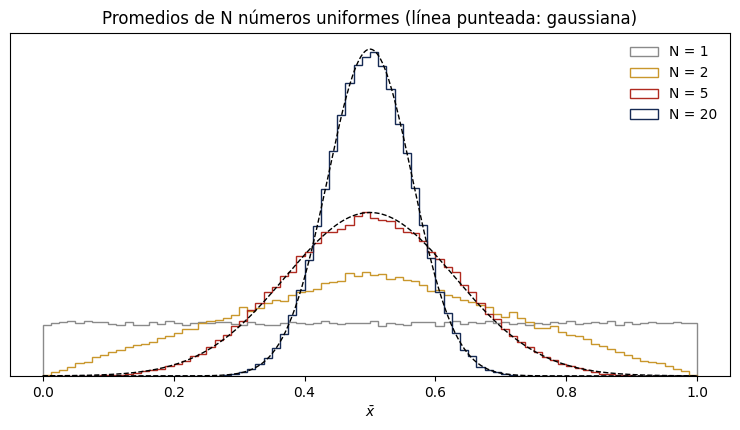

In [72]:
# Histogramas de los promedios y gaussiana del teorema
import numpy as np
import matplotlib.pyplot as plt
datos = np.loadtxt("tcl.dat")
xs = np.linspace(0, 1, 400)
plt.figure(figsize=(7.5, 4.4))
for col, (N, color) in enumerate(zip([1, 2, 5, 20], ["#8A8A8A", "#C9972C", "#B02A20", "#162A54"])):
    plt.hist(datos[:, col], bins=np.linspace(0, 1, 81), density=True, histtype="step",
             lw=1.6, color=color, label=f"N = {N}")
    if N >= 5:
        s = np.sqrt(1/12)/np.sqrt(N)
        plt.plot(xs, np.exp(-(xs - 0.5)**2/(2*s**2))/(np.sqrt(2*np.pi)*s), "k--", lw=1)
plt.xlabel(r"$\bar x$"); plt.yticks([]); plt.legend(frameon=False)
plt.title("Promedios de N números uniformes (línea punteada: gaussiana)")
plt.tight_layout(); plt.show()